# Render a Skeleton Example

This notebook loads one sample from `Dataset/skeleton/raw`, applies the same preprocessing as `training/preprocessing.py`, and renders the result.

- no carry-forward of the last valid frame
- hands are flattened for model input
- `NaN` values are converted to `0.0`

Channels are `[x, y, z, visibility, presence]`.


In [4]:
%matplotlib inline

from pathlib import Path

import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

from training.preprocessing import LANDMARK_CHANNEL_COUNT, preprocess_component_array

DATA_ROOT = Path("Dataset/skeleton/raw")
DEFAULT_EXAMPLE = "06783829233746763-STACK 4"
PART_DIRS = {
    "body": DATA_ROOT / "body",
    "hand": DATA_ROOT / "hand",
    "face": DATA_ROOT / "face",
}

available_examples = sorted(
    {
        path.stem
        for part_dir in PART_DIRS.values()
        if part_dir.exists()
        for path in part_dir.glob("*.npy")
        if path.name != "keypoint_index.npy"
    }
)

if not available_examples:
    raise FileNotFoundError(f"No skeleton .npy examples found under {DATA_ROOT}")

EXAMPLE_STEM = DEFAULT_EXAMPLE if DEFAULT_EXAMPLE in available_examples else available_examples[0]
print("Available examples:", available_examples)
print("Using example:", EXAMPLE_STEM)


def load_preprocessed_part(part_name):
    npy_path = PART_DIRS[part_name] / f"{EXAMPLE_STEM}.npy"
    if not npy_path.exists():
        print(f"{part_name}: missing ({npy_path})")
        return None
    raw = np.load(npy_path)
    processed = preprocess_component_array(part_name, raw)
    print(f"{part_name}: loaded {npy_path} with raw shape {raw.shape} -> processed shape {processed.shape}")
    return processed


body = load_preprocessed_part("body")
hands = load_preprocessed_part("hand")
face = load_preprocessed_part("face")

loaded_parts = {
    "body": body,
    "hand": hands,
    "face": face,
}
loaded_parts = {name: data for name, data in loaded_parts.items() if data is not None}
if not loaded_parts:
    raise FileNotFoundError(f"No .npy data found for example {EXAMPLE_STEM}")

part_frame_counts = {name: len(data) for name, data in loaded_parts.items()}
if any(count == 0 for count in part_frame_counts.values()):
    raise ValueError(f"Example {EXAMPLE_STEM} contains an empty .npy array: {part_frame_counts}")

frame_count = max(part_frame_counts.values())
print("processed frame counts:", part_frame_counts)
print("render frame count:", frame_count)

hands_for_render = None if hands is None else hands.reshape(hands.shape[0], 2, 21, LANDMARK_CHANNEL_COUNT)
if hands is not None:
    print("hand model shape:", hands.shape)

body_index_path = PART_DIRS["body"] / "keypoint_index.npy"
hand_index_path = PART_DIRS["hand"] / "keypoint_index.npy"
face_index_path = PART_DIRS["face"] / "keypoint_index.npy"

body_index = np.load(body_index_path, allow_pickle=True).item() if body_index_path.exists() else None
hand_index = np.load(hand_index_path, allow_pickle=True).item() if hand_index_path.exists() else None
face_index = np.load(face_index_path, allow_pickle=True).item() if face_index_path.exists() else None


Available examples: ['000017451997373907346-LIBRARY', '0000197996356050556-CELERY', '000039681044643247176-PUSH', '00010630150123391857-CANDY 1', '00012571487478130194-CASTLE 2', '0001523804663805528-PASSPORT', '00015575668519507424-GOVERNMENT', '00017673589179367788-OPINION 1', '00019179295562565812-NOT INTERESTED', '0001980973749611259-PJS', '0002081503807414009-INHALE', '0002339698736220086-seedCORN 2', '00024159033092296944-LIVE 2', '0002573120929312278-WORKSHOP', '0002600716749214804-VOMIT', '0002752583837435374-DISCUSS', '0002865632478359359-UNCLE', '00033277435717016246-ELECTROCUTE', '0003343346024893279-EASTER', '00034492371095096175-BAG 2', '0003562642815786443-EYE TURN', '000361134873257285-STRAWBERRY 2', '0003612029398618599-MACHINE', '0003714747508705152-CREWCUT', '0003730820903873333-NEWS TO_ME', '0004410884919203717-HEADPHONES', '0004612869367546235-ACCENT', '00048437403594836503-JUICE 2', '0004934454947953526-PIG', '0004970838496565211-GUIDE', '0005037273854926472-TIGER'

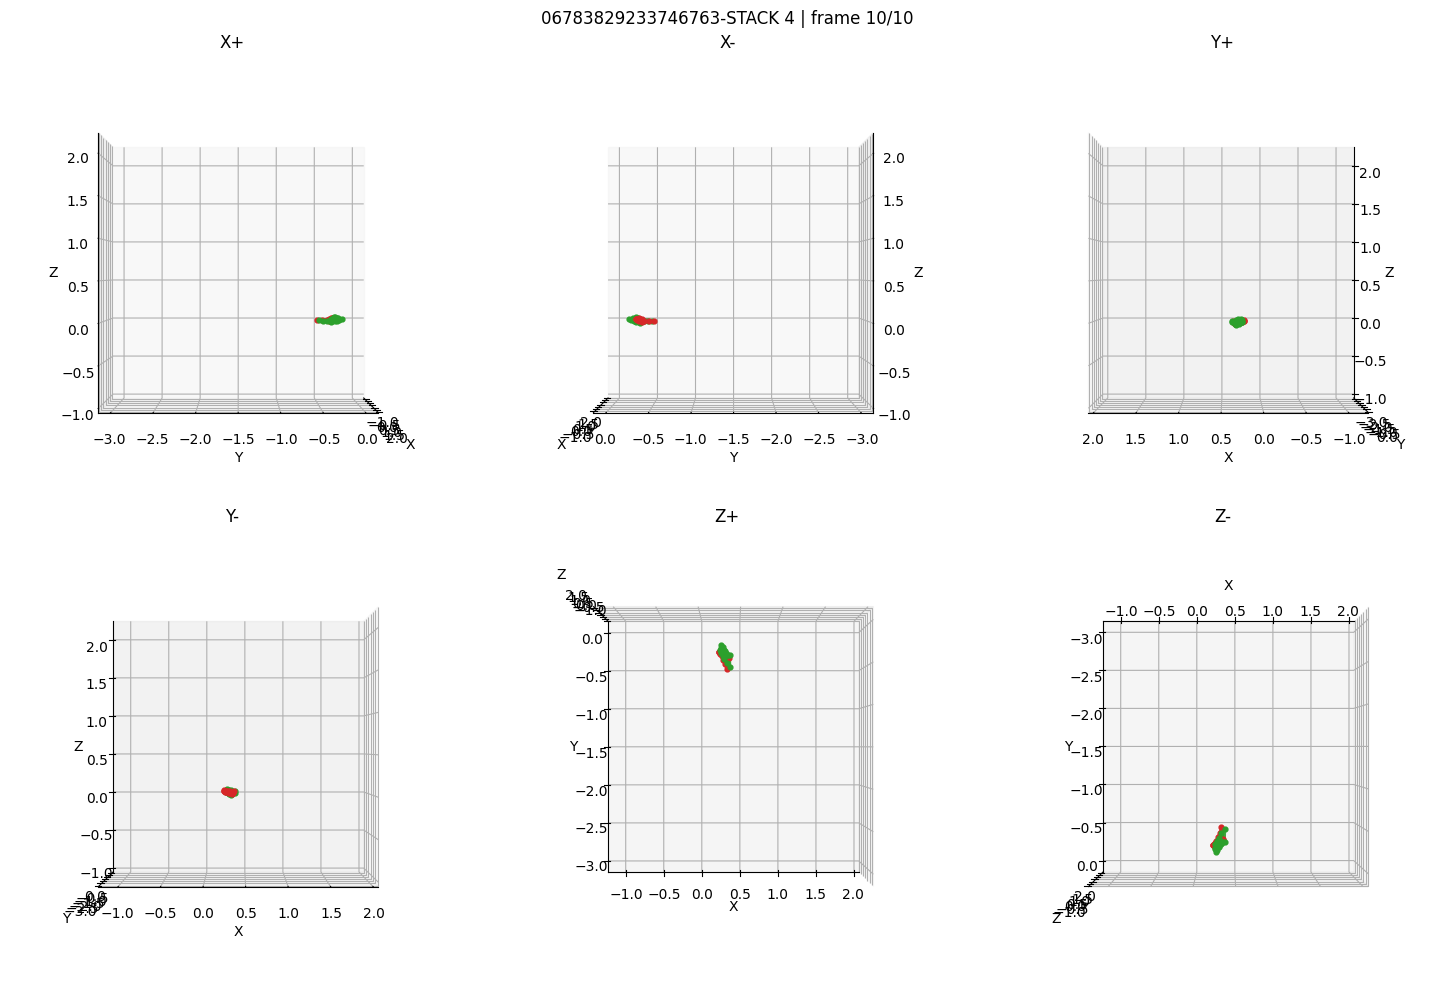

In [5]:
BODY_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3),
    (0, 4), (4, 5), (5, 6),
    (9, 10),
    (11, 12),
    (11, 13), (13, 15),
    (15, 17), (15, 19), (15, 21),
    (17, 19),
    (12, 14), (14, 16),
    (16, 18), (16, 20), (16, 22),
    (18, 20),
    (11, 23), (12, 24), (23, 24),
    (23, 25), (25, 27), (27, 29), (27, 31),
    (24, 26), (26, 28), (28, 30), (28, 32),
    (29, 31), (30, 32),
]

HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12),
    (9, 13), (13, 14), (14, 15), (15, 16),
    (13, 17), (17, 18), (18, 19), (19, 20),
    (0, 17),
]

VIEW_SPECS = [
    ("X+", 0, 0),
    ("X-", 0, 180),
    ("Y+", 0, 90),
    ("Y-", 0, -90),
    ("Z+", 90, -90),
    ("Z-", -90, -90),
]


def extract_xyz(points):
    xs = points[:, 0].astype(float)
    ys = -points[:, 1].astype(float)
    zs = -points[:, 2].astype(float)
    return xs, ys, zs


def build_connection_coords(points, connections):
    x_lines, y_lines, z_lines = [], [], []
    xs, ys, zs = extract_xyz(points)
    for start, end in connections:
        x_lines.extend([xs[start], xs[end], np.nan])
        y_lines.extend([ys[start], ys[end], np.nan])
        z_lines.extend([zs[start], zs[end], np.nan])
    return x_lines, y_lines, z_lines


def iter_landmark_groups(frame_idx, show_face=True):
    if hands_for_render is not None and frame_idx < len(hands_for_render):
        yield hands_for_render[frame_idx, 0]
        yield hands_for_render[frame_idx, 1]
    if body is not None and frame_idx < len(body):
        yield body[frame_idx]
    if show_face and face is not None and frame_idx < len(face):
        yield face[frame_idx]


def gather_bounds(show_face=True):
    xs_all, ys_all, zs_all = [], [], []
    for frame_idx in range(frame_count):
        for points in iter_landmark_groups(frame_idx, show_face=show_face):
            xs, ys, zs = extract_xyz(points)
            xs_all.extend(xs.tolist())
            ys_all.extend(ys.tolist())
            zs_all.extend(zs.tolist())
    if not xs_all:
        return (-1.0, 1.0), (-1.0, 1.0), (-1.0, 1.0)
    x_min, x_max = min(xs_all), max(xs_all)
    y_min, y_max = min(ys_all), max(ys_all)
    z_min, z_max = min(zs_all), max(zs_all)
    span = max(x_max - x_min, y_max - y_min, z_max - z_min, 1e-6)
    x_mid = (x_min + x_max) / 2
    y_mid = (y_min + y_max) / 2
    z_mid = (z_min + z_max) / 2
    half = span / 2
    pad = span * 0.05
    return (
        (x_mid - half - pad, x_mid + half + pad),
        (y_mid - half - pad, y_mid + half + pad),
        (z_mid - half - pad, z_mid + half + pad),
    )


def style_axis(ax, title, bounds, elev, azim):
    x_limits, y_limits, z_limits = bounds
    ax.set_xlim(*x_limits)
    ax.set_ylim(*y_limits)
    ax.set_zlim(*z_limits)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_title(title)
    ax.view_init(elev=elev, azim=azim)
    try:
        ax.set_box_aspect((1, 1, 1))
    except AttributeError:
        pass


def draw_landmark_group(ax, points, color, size, connections=None, line_width=1.5):
    xs, ys, zs = extract_xyz(points)
    ax.scatter(xs, ys, zs, c=color, s=size, depthshade=False)
    if connections:
        x_lines, y_lines, z_lines = build_connection_coords(points, connections)
        ax.plot(x_lines, y_lines, z_lines, color=color, linewidth=line_width, alpha=0.9)


def draw_frame(ax, frame_idx, show_face=True):
    if hands_for_render is not None and frame_idx < len(hands_for_render):
        draw_landmark_group(ax, hands_for_render[frame_idx, 0], "#d62728", 12, HAND_CONNECTIONS, 1.8)
        draw_landmark_group(ax, hands_for_render[frame_idx, 1], "#2ca02c", 12, HAND_CONNECTIONS, 1.8)
    # if body is not None and frame_idx < len(body):
    #     draw_landmark_group(ax, body[frame_idx], "#1f77b4", 10, BODY_CONNECTIONS, 1.8)
    if show_face and face is not None and frame_idx < len(face):
        draw_landmark_group(ax, face[frame_idx], "#9467bd", 3)


BOUNDS_WITH_FACE = gather_bounds(show_face=True)
BOUNDS_NO_FACE = gather_bounds(show_face=False)


def plot_frame(frame_idx, show_face=True):
    bounds = BOUNDS_WITH_FACE if show_face and face is not None else BOUNDS_NO_FACE
    fig, axes = plt.subplots(2, 3, figsize=(15, 10), subplot_kw={"projection": "3d"})
    axes = axes.ravel()
    for ax, (title, elev, azim) in zip(axes, VIEW_SPECS):
        style_axis(ax, title, bounds, elev, azim)
        draw_frame(ax, frame_idx, show_face=show_face)
    fig.suptitle(f"{EXAMPLE_STEM} | frame {frame_idx + 1}/{frame_count}")
    plt.tight_layout()
    plt.show()


frame_idx = min(10, frame_count - 1)
plot_frame(frame_idx)


In [6]:
def animate_example(step=1, show_face=True):
    frame_indices = list(range(0, frame_count, step)) or [0]
    bounds = BOUNDS_WITH_FACE if show_face and face is not None else BOUNDS_NO_FACE
    fig, axes = plt.subplots(2, 3, figsize=(15, 10), subplot_kw={"projection": "3d"})
    axes = axes.ravel()

    def update(i):
        frame_idx = frame_indices[i]
        for ax, (title, elev, azim) in zip(axes, VIEW_SPECS):
            ax.cla()
            style_axis(ax, title, bounds, elev, azim)
            draw_frame(ax, frame_idx, show_face=show_face)
        fig.suptitle(f"{EXAMPLE_STEM} | frame {frame_idx + 1}/{frame_count}")
        return []

    update(0)
    anim = animation.FuncAnimation(
        fig,
        update,
        frames=len(frame_indices),
        interval=50,
        blit=False,
        repeat=True,
    )
    plt.tight_layout()
    plt.close(fig)
    return HTML(anim.to_jshtml())


display(animate_example(step=1, show_face=True))
